# 12 · When every pair statistic agrees

Use two arrangements on a 12-site ring. Each contains the same two oriented image motifs in the same proportions. Their realized tilewise Q-fields have identical cyclic pair correlations. A third-order statistic separates them exactly.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import power, bispectrum
from observables.patterns import homometric
from observables.stage3 import (tile_library, render, tile_q, cyclic_statistics, matrix_profile,
                                crop_census, orbit, FAMILIES, CONDITIONS, METHODS, run)
OUT = ROOT/'results'/'stage3'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
a, b = homometric()

## Construct the fields
Let $x_i\in\{0,1\}$ record which motif occupies site $i$. For each image tile, compute the real second circular moment $q_i=\Re m_2$. Transposing a motif swaps its gradient axes and negates this component. Thus $q_i=\alpha(1-2x_i)$ for a fixed nonzero $\alpha$. The tile frame is given and the comparison allows only cyclic translations in that frame.

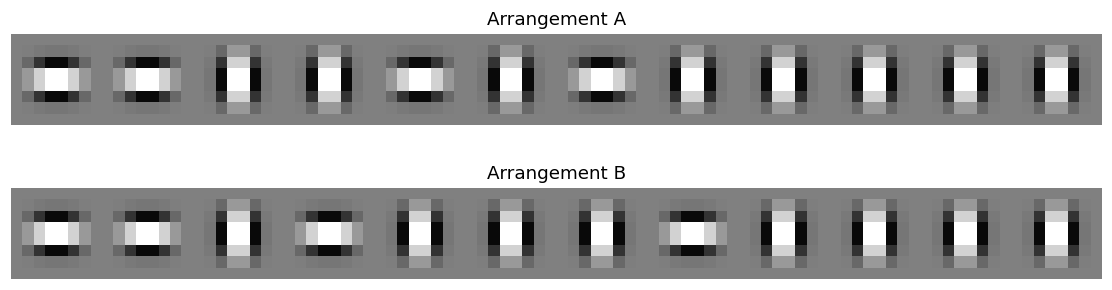

In [3]:
library=tile_library('windowed wave')
images=[render(x,library) for x in (a,b)]
qa,qb=map(tile_q,images)
amplitude=qa[a==0][0]
assert abs(amplitude)>.1
np.testing.assert_allclose(qa,amplitude*(1-2*a),atol=1e-12)
np.testing.assert_allclose(qb,amplitude*(1-2*b),atol=1e-12)
assert not any(np.array_equal(a,x) for x in [*orbit(b),*orbit(b[::-1])])
fig,axes=plt.subplots(2,1,figsize=(10,2.8))
limit=np.max(abs(library))
for label,ax,image in zip('AB',axes,images):
    ax.imshow(image,cmap='gray',vmin=-limit,vmax=limit,aspect='equal')
    ax.set_title(f'Arrangement {label}');ax.set_axis_off()
show('12_homometric_motifs')

## Check two-point equality and exhibit a three-point witness
Use $s=2x-1$ to remove the arbitrary sign and scale of the image feature for this exact construction.
$C(r)=N^{-1}\sum_i s_i s_{i+r}$ and $T(r,t)=N^{-1}\sum_i s_i s_{i+r}s_{i+t}$, with all indices modulo $N$. The normalized sign sequence is a proof device. The retrieval benchmark uses measured $q$ directly.

For any lag, the $2\times2$ table of joint binary states is determined by the one-site counts and the count of $(1,1)$ pairs. Equality of both therefore implies equality of **all** cyclic two-site observables that use these two motif states, including the full lag matrix after any fixed map of the state into a feature vector.

T(1,4) = 0.666667 for A and 0.000000 for B


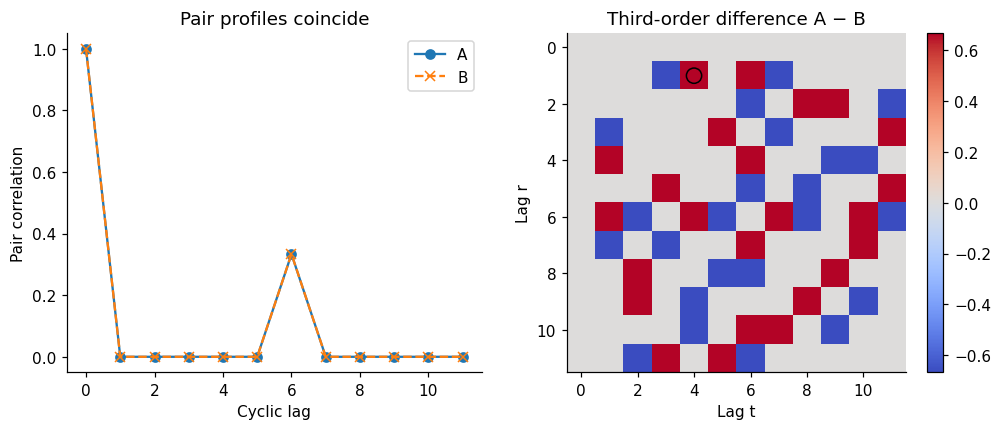

In [5]:
sa,sb=2*a-1,2*b-1
pa,ta=cyclic_statistics(sa);pb,tb=cyclic_statistics(sb)
np.testing.assert_array_equal(pa,pb)
np.testing.assert_allclose(power(qa),power(qb),atol=1e-12)
np.testing.assert_allclose(matrix_profile(np.eye(2)[a.astype(int)]),
                           matrix_profile(np.eye(2)[b.astype(int)]),atol=1e-12)
assert np.isclose(ta[1,4],2/3) and np.isclose(tb[1,4],0)
print(f'T(1,4) = {ta[1,4]:.6f} for A and {tb[1,4]:.6f} for B')
fig,axes=plt.subplots(1,2,figsize=(9,3.8))
axes[0].plot(pa,'o-',label='A');axes[0].plot(pb,'x--',label='B')
axes[0].set(xlabel='Cyclic lag',ylabel='Pair correlation',title='Pair profiles coincide');axes[0].legend()
limit=np.max(np.abs(ta-tb))
heat=axes[1].imshow(ta-tb,cmap='coolwarm',vmin=-limit,vmax=limit)
axes[1].scatter(4,1,facecolors='none',edgecolors='black',s=100)
axes[1].set(xlabel='Lag t',ylabel='Lag r',title='Third-order difference A − B')
fig.colorbar(heat,ax=axes[1]);show('12_pair_and_triple')

## Interpretation
The triplet observable tests whether three orientations co-occur in a specified relative arrangement. Its Fourier counterpart is the bispectrum. They encode the same third-order information under consistent periodic conventions. This witness establishes separation for the chosen pair. Later we compare the full triplet profile against exact alignment and test its sensitivity to noise.